# 12 · Two dimensions

Nothing in the method of lines changes in two dimensions except the size of the system and the shape of its
Jacobian: an n × n grid gives n² unknowns, and the five-point Laplacian couples each point to its neighbours
in both directions, so the Jacobian has a band of width n (the Kronecker structure). Banded elimination still
costs only n² · n² = n⁴ flops per factorisation - far below the n⁶ of a dense one - and the implicit methods
remain practical. This notebook solves heat in a plate with the Kronecker band, grows a circular reaction
front, and finishes with the lid-driven cavity, a genuine fluid-dynamics computation whose steady state is
compared with the classic benchmark.

**What you will learn**
- flatten 2-D fields and know the Kronecker band of their Jacobian
- solve 2-D parabolic problems implicitly with banded Newton
- measure fronts in 2-D
- set up a vorticity-streamfunction flow solver and check it against a benchmark

**Before you start:** notebooks 03 and 06  ·  **Time:** about 90 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, stencils as st, stiffness, grids
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The Kronecker structure

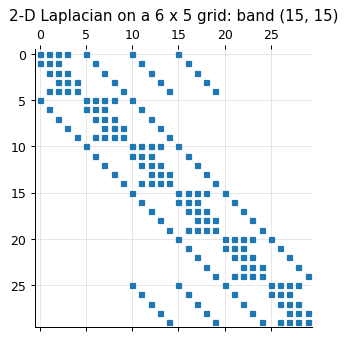

the x-stencil couples point (i, j) to (i +- 1, j), which sits ny = 5 positions away in the flattened vector: band = ny * (half-width of Ax including its closures)


In [2]:
Ax = st.diff_operator(np.linspace(0, 1, 6), 2, 2)
Ay = st.diff_operator(np.linspace(0, 1, 5), 2, 2)
apply2, band = st.kron_sum(Ax, Ay)
K = np.kron(Ax.to_dense(), np.eye(5)) + np.kron(np.eye(6), Ay.to_dense())
plt.spy(np.abs(K) > 1e-12, markersize=4); plt.title(f"2-D Laplacian on a 6 x 5 grid: band {band}"); plt.show()
print("the x-stencil couples point (i, j) to (i +- 1, j), which sits ny = 5 positions away in the flattened vector: band = ny * (half-width of Ax including its closures)")

Flattening the field row by row, a neighbour in y is one position away and a neighbour in x is n_y positions
away, so the 2-D operator A_x ⊗ I + I ⊗ A_y has a band of n_y times the x-stencil's half-width. `kron_sum`
applies it without forming the matrix (two 1-D operator applications on the reshaped field) and reports the
band for the implicit solvers.

## Heat in a plate

heat in a plate (2-D): 625 unknowns, band (25, 25); error vs sin(pi x) sin(2 pi y) exp(-5 pi^2 t) = 1.1e-03; 1 Jacobian, 2.8 Newton per step


spatial order 2.00
Dormand-Prince for comparison: 66 steps (stability-limited near 3.3 dx^2/8 = 7.2e-04), error 1.0e-03


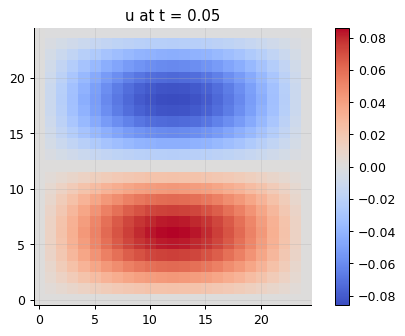

In [3]:
p = pr.plate_heat_2d(n=24)
s = p.solve("bdf", 1e-3, order=4, n_out=1)
print(f"{p.name}: {p.n} unknowns, band {p.band}; error vs sin(pi x) sin(2 pi y) exp(-5 pi^2 t) = {p.error(s):.1e}; {s.jacobian_evaluations} Jacobian, {s.newton_iterations / s.steps:.1f} Newton per step")
errs = [pr.plate_heat_2d(n=n).error(pr.plate_heat_2d(n=n).solve("bdf", 5e-4, order=4)) for n in (12, 24)]
print(f"spatial order {np.log2(errs[0] / errs[1]):.2f}")
sd = p.solve("dopri", rtol=1e-8, atol=1e-10, n_out=1)
print(f"Dormand-Prince for comparison: {sd.steps} steps (stability-limited near 3.3 dx^2/8 = {3.3 * p.grid.gx.dx**2 / 8:.1e}), error {p.error(sd):.1e}")
plt.imshow(s.y[-1].reshape(p.params["shape"]).T, origin="lower", cmap="coolwarm"); plt.title("u at t = 0.05"); plt.colorbar(); plt.show()

The 625-point plate is solved by BDF4 with one banded Jacobian of width 25 for the whole run, about two
Newton iterations per step, and second-order spatial accuracy. In 2-D the explicit limit is about 3.3Δx²/(8κ)
- the two-directional Laplacian has eigenvalues down to −8κ/Δx² - and the adaptive explicit solver takes
more steps than BDF4 for a run of 0.05; the gap widens as the grid is refined.

## A circular reaction front

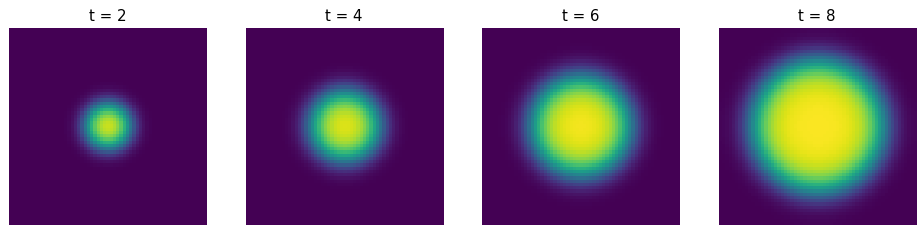

front radius [ 3.07  4.07  6.46  9.54 12.86]; speeds [0.5  1.2  1.54 1.66] -> approaching the planar 2 sqrt(rD) = 2 as the curvature correction D/R fades
3721 unknowns, band 61: 1 Jacobian, 5.7 Newton per step


In [4]:
p = pr.fisher_2d(n=60)
s = p.solve("bdf", 0.05, order=2, n_out=4)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, t, y in zip(axes, s.t[1:], s.y[1:]):
    ax.imshow(y.reshape(p.params["shape"]).T, origin="lower", extent=(0, 40, 0, 40), cmap="viridis", vmin=0, vmax=1); ax.set_title(f"t = {t:.0f}"); ax.axis("off")
plt.show()
rad = np.array([np.sqrt(np.mean(y > 0.5) * 40.0**2 / np.pi) for y in s.y])
print(f"front radius {np.round(rad, 2)}; speeds {np.round(np.diff(rad) / np.diff(s.t), 2)} -> approaching the planar 2 sqrt(rD) = 2 as the curvature correction D/R fades")
print(f"{p.n} unknowns, band {p.band[0]}: {s.jacobian_evaluations} Jacobian, {s.newton_iterations / s.steps:.1f} Newton per step")

The 3721-unknown system has a band of 61 and BDF2 needs several Newton iterations per step (the nonlinear
reaction) with one Jacobian for the run. The front's speed increases with its radius as 2 − D/R: curvature
costs speed.

## The lid-driven cavity

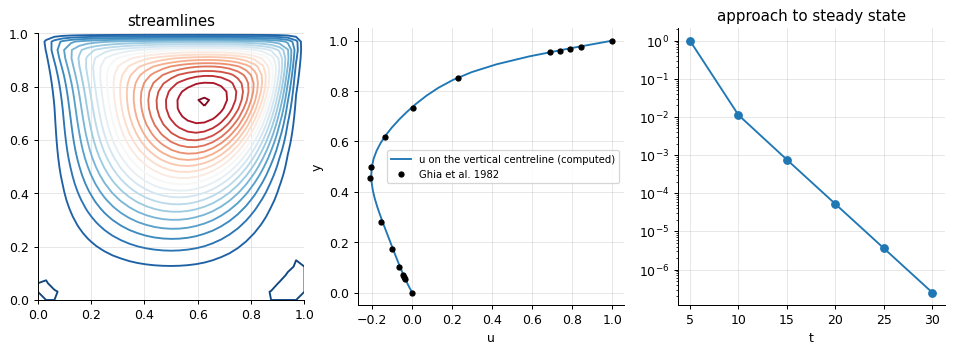

u_min on the vertical centreline -0.2041 at y = 0.469 (Ghia: -0.2109 at 0.4531); primary vortex psi_min -0.1004 (Ghia: -0.1034)


In [5]:
p = pr.cavity_flow(n=32, Re=100.0)
s = p.solve("rk4", 0.004, n_out=6)
n = 33
omega = s.y[-1].reshape(n, n)
psi = p.params["streamfunction"](omega)
u, v = p.params["velocity"](psi)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].contour(p.x, p.x, psi.T, 20, cmap="RdBu"); axes[0].set_aspect("equal"); axes[0].set_title("streamlines")
axes[1].plot(u[16, :], p.x, label="u on the vertical centreline (computed)")
ghia_y = [0.0, 0.0547, 0.0625, 0.0703, 0.1016, 0.1719, 0.2813, 0.4531, 0.5, 0.6172, 0.7344, 0.8516, 0.9531, 0.9609, 0.9688, 0.9766, 1.0]
ghia_u = [0.0, -0.03717, -0.04192, -0.04775, -0.06434, -0.10150, -0.15662, -0.21090, -0.20581, -0.13641, 0.00332, 0.23151, 0.68717, 0.73722, 0.78871, 0.84123, 1.0]
axes[1].plot(ghia_u, ghia_y, "ko", ms=4, label="Ghia et al. 1982"); axes[1].legend(fontsize=8); axes[1].set_xlabel("u"); axes[1].set_ylabel("y")
axes[2].semilogy(s.t[1:], [np.max(np.abs(s.y[i] - s.y[i - 1])) / np.max(np.abs(s.y[-1])) for i in range(1, len(s.t))], "o-"); axes[2].set_title("approach to steady state"); axes[2].set_xlabel("t")
plt.show()
print(f"u_min on the vertical centreline {u[16, :].min():.4f} at y = {p.x[np.argmin(u[16, :])]:.3f} (Ghia: -0.2109 at 0.4531); primary vortex psi_min {psi.min():.4f} (Ghia: -0.1034)")

In vorticity-streamfunction form the Navier-Stokes equations become one transport equation for the vorticity
(advected by the velocity, diffused by 1/Re) and a Poisson equation for the streamfunction solved at every
right-hand-side evaluation (its operator is factorised once); the velocity follows from the streamfunction and
the wall vorticity from Thom's formula. At Re = 100 on a 32 × 32 grid, explicit RK4 reaches the steady state
in a few thousand cheap steps - the viscous time scale Δx²Re/4 ≈ 0.016 limits the step, but the Poisson solve
makes implicit treatment unattractive - and the centreline velocity and vortex strength agree with Ghia,
Ghia and Shin's benchmark within the few percent expected of this grid.

## Inside the algorithm: the 2-D Laplacian from two 1-D ones

In [6]:
U = np.random.default_rng(0).normal(size=(6, 5))
by_hand = Ax.matvec(U) + Ay.matvec(U.T).T
print("kron_sum vs two 1-D applications:", np.max(np.abs(apply2(U.ravel()) - by_hand.ravel())), "; vs the dense Kronecker matrix:", np.max(np.abs(K @ U.ravel() - by_hand.ravel())))

kron_sum vs two 1-D applications: 0.0 ; vs the dense Kronecker matrix: 2.842170943040401e-14


## Exercises
1. Solve the plate problem on grids of 12, 24 and 48 intervals with BDF4 and record the Jacobian factorisation time (use `time.perf_counter` around `linalg.lu_banded` on the Jacobian). Confirm the n^4 cost law and compare with a dense `numpy.linalg.solve` of the same system.
2. Run the cavity at Re = 400 on the 32 x 32 grid and on 48 x 48 (`cavity_flow(n=48, Re=400)`). Compare u_min on the centreline with Ghia's -0.3273 at y = 0.2813, and the time to steady state.
3. **Implement it yourself:** write the 2-D heat right-hand side with Neumann ghosts on all four sides and verify that the total heat is conserved; then find the band of its Jacobian with `linalg.banded_jacobian` and check it against the dense one.